# Assessment 2 — City Water Network Monitoring


In [ ]:
from google.colab import files
import zipfile, os, glob
uploaded = files.upload()
for fn in uploaded:
    if fn.lower().endswith('.zip'):
        with zipfile.ZipFile(fn) as z: z.extractall('/content/assessment_files')
print('Extracted files')
for root, dirs, fs in os.walk('/content/assessment_files'):
    for f in fs: print(os.path.join(root, f))

Saving Assessment 2-20261111T035249Z-1-001.zip to Assessment 2-20261111T035249Z-1-001.zip
Extracted files
/content/assessment_files/Assessment 2/Databricks_Water_Assessment/water_meter_readings.csv
/content/assessment_files/Assessment 2/Databricks_Water_Assessment/water_readings_incremental.csv
/content/assessment_files/Assessment 2/Databricks_Water_Assessment/databricks_setup.py
/content/assessment_files/Assessment 2/Databricks_Water_Assessment/water_zones.json
/content/assessment_files/Assessment 2/Databricks_Water_Assessment/README.md
/content/assessment_files/Assessment 2/Databricks_Water_Assessment/assessment_questions.md
/content/assessment_files/Assessment 2/Databricks_Water_Assessment/water_service_requests.csv
/content/assessment_files/Assessment 2/Databricks_Water_Assessment/water_reading_changes.csv
/content/assessment_files/Assessment 2/Databricks_Water_Assessment/assessment.pdf


In [ ]:
!pip -q install pyspark==3.5.1 delta-spark==3.2.0

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.


In [ ]:
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq

import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.21.0.3+1-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.21.0.3+1-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.011s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't

In [ ]:
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.window import Window
from delta import configure_spark_with_delta_pip

builder = (SparkSession.builder
    .appName('AssessmentColab')
    .master('local[*]')
    .config('spark.sql.extensions', 'io.delta.sql.DeltaSparkSessionExtension')
    .config('spark.sql.catalog.spark_catalog', 'org.apache.spark.sql.delta.catalog.DeltaCatalog'))

spark = configure_spark_with_delta_pip(builder).getOrCreate()
print('Spark Version:', spark.version)

Spark Version: 3.5.1


In [ ]:
all_roots = []
for root, dirs, fs in os.walk('/content/assessment_files'):
    if 'water_meter_readings.csv' in fs:
        all_roots.append(root)
assert all_roots, 'Could not find the expected CSV. Check that the correct ZIP was uploaded.'
DATA = all_roots[0]
print('DATA =', DATA)

DATA = /content/assessment_files/Assessment 2/Databricks_Water_Assessment


## A. SQL querying and filtering (Questions 1–5)

### Question 1: Load data and inspect counts

In [ ]:
readings=spark.read.option('header',True).option('inferSchema',True).csv(f'{DATA}/water_meter_readings.csv')
zones=spark.read.json(f'{DATA}/water_zones.json')
requests=spark.read.option('header',True).option('inferSchema',True).csv(f'{DATA}/water_service_requests.csv')
changes=spark.read.option('header',True).option('inferSchema',True).csv(f'{DATA}/water_reading_changes.csv')
incremental=spark.read.option('header',True).option('inferSchema',True).csv(f'{DATA}/water_readings_incremental.csv')
for n,d in [('readings',readings),('zones',zones),('requests',requests),('changes',changes),('incremental',incremental)]: print(n,d.count()); d.show(5,False)
readings.createOrReplaceTempView('water_meter_readings_source')
zones.createOrReplaceTempView('water_zones')
requests.createOrReplaceTempView('water_service_requests')
changes.createOrReplaceTempView('water_reading_changes')
readings.printSchema()

readings 157
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1001      |M001    |W01    |2026-10-01 07:00:00|39.1    |3.56        |0.75         |2365              |Valid         |Gateway      |
|1002      |M002    |W02    |2026-10-01 08:10:00|59.9    |4.6         |0.39         |3545              |Valid         |SmartMeter   |
|1003      |M003    |W03    |2026-10-01 09:20:00|25.7    |2.22        |1.15         |548               |Valid         |FieldApp     |
|1004      |M004    |W04    |2026-10-01 10:00:00|56.7    |2.84        |1.1          |2871              |Valid         |Gateway      |
|1005      |M005    |W05    |2026-10-01 11:10:00|

### Question 2: Filter Valid Status Readings

In [ ]:
spark.sql("SELECT reading_id,meter_id,zone_id,reading_time,consumption_liters FROM water_meter_readings_source WHERE reading_status='Valid'").show(30,False)

+----------+--------+-------+-------------------+------------------+
|reading_id|meter_id|zone_id|reading_time       |consumption_liters|
+----------+--------+-------+-------------------+------------------+
|1001      |M001    |W01    |2026-10-01 07:00:00|2365              |
|1002      |M002    |W02    |2026-10-01 08:10:00|3545              |
|1003      |M003    |W03    |2026-10-01 09:20:00|548               |
|1004      |M004    |W04    |2026-10-01 10:00:00|2871              |
|1006      |M006    |W06    |2026-10-01 12:20:00|2171              |
|1007      |M007    |W07    |2026-10-01 13:00:00|4167              |
|1008      |M008    |W08    |2026-10-01 14:10:00|3621              |
|1009      |M009    |W09    |2026-10-01 15:20:00|1609              |
|1010      |M010    |W10    |2026-10-01 16:00:00|1829              |
|1011      |M011    |W01    |2026-10-02 07:10:00|313               |
|1013      |M013    |W03    |2026-10-02 09:00:00|2071              |
|1014      |M014    |W04    |2026-

### Question 3: Filter Low Pressure (< 2.5 bar)

In [ ]:
spark.sql('SELECT * FROM water_meter_readings_source WHERE pressure_bar < 2.5 ORDER BY pressure_bar ASC').show(100,False)

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1071      |M011    |W01    |2026-10-08 07:10:00|10.9    |1.8         |0.8          |647               |Valid         |SmartMeter   |
|1064      |M004    |W04    |2026-10-07 10:00:00|20.3    |1.82        |0.84         |708               |Valid         |Gateway      |
|1024      |M024    |W04    |2026-10-03 10:20:00|44.5    |1.83        |1.25         |2085              |Valid         |FieldApp     |
|1116      |M026    |W06    |2026-10-12 12:10:00|28.9    |1.84        |0.36         |1692              |Valid         |SmartMeter   |
|1133      |M013    |W03    |2026-10-14 09:00:00|15.6    |1.86

### Question 4: Filter Moderate Flow & Specific Source Systems

In [ ]:
spark.sql("SELECT * FROM water_meter_readings_source WHERE flow_lpm BETWEEN 20 AND 50 AND source_system IN ('Gateway','SmartMeter')").show(100,False)

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1001      |M001    |W01    |2026-10-01 07:00:00|39.1    |3.56        |0.75         |2365              |Valid         |Gateway      |
|1014      |M014    |W04    |2026-10-02 10:10:00|22.4    |4.73        |0.5          |1108              |Valid         |SmartMeter   |
|1017      |M017    |W07    |2026-10-02 13:10:00|28.0    |3.77        |1.08         |1318              |Valid         |SmartMeter   |
|1019      |M019    |W09    |2026-10-02 15:00:00|23.0    |4.34        |0.28         |1091              |Valid         |Gateway      |
|1022      |M022    |W02    |2026-10-03 08:00:00|32.5    |3.35

### Question 5: Count Readings by Status

In [ ]:
spark.sql('SELECT reading_status,COUNT(*) AS reading_count FROM water_meter_readings_source GROUP BY reading_status ORDER BY reading_status').show()

+--------------+-------------+
|reading_status|reading_count|
+--------------+-------------+
|      Rejected|            9|
|       Suspect|           11|
|         Valid|          137|
+--------------+-------------+



## B. Joins, aggregations and windows (Questions 6–10)

### Question 6: Inner Join Readings and Zone Metadata

In [ ]:
zones_flat=zones.select('zone_id','zone_name',F.col('location.district').alias('district'),'zone_type','daily_capacity_liters')
readings.createOrReplaceTempView('r'); zones_flat.createOrReplaceTempView('z')
spark.sql('SELECT z.zone_name,z.district,r.meter_id,r.consumption_liters FROM r JOIN z USING(zone_id)').show(100,False)

+------------------+--------+--------+------------------+
|zone_name         |district|meter_id|consumption_liters|
+------------------+--------+--------+------------------+
|Old City          |Central |M001    |2365              |
|Hill View         |North   |M002    |3545              |
|Market District   |Central |M003    |548               |
|Lake Side         |West    |M004    |2871              |
|University Quarter|East    |M005    |2656              |
|Industrial Estate |South   |M006    |2171              |
|Garden Colony     |North   |M007    |4167              |
|Transit Hub       |East    |M008    |3621              |
|Riverfront        |West    |M009    |1609              |
|South Extension   |South   |M010    |1829              |
|Old City          |Central |M011    |313               |
|Hill View         |North   |M012    |1303              |
|Market District   |Central |M013    |2071              |
|Lake Side         |West    |M014    |1108              |
|University Qu

### Question 7: Identify Unknown / Unmatched Zones (Left Anti Join)

In [ ]:
readings.join(zones_flat.select('zone_id'),'zone_id','left_anti').show(100,False)

+-------+----------+--------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|zone_id|reading_id|meter_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+-------+----------+--------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|W99    |1154      |M999    |2026-10-16 11:00:00|24.5    |3.0         |0.45         |1150              |Valid         |FieldApp     |
|NULL   |1156      |M012    |2026-10-16 12:30:00|28.0    |3.1         |0.52         |870               |Valid         |Gateway      |
+-------+----------+--------+-------------------+--------+------------+-------------+------------------+--------------+-------------+



### Question 8: Identify Zones with No Active Meter Readings

In [ ]:
zones_flat.join(readings.select('zone_id').distinct(),'zone_id','left_anti').show()

+-------+---------------+--------+---------+---------------------+
|zone_id|      zone_name|district|zone_type|daily_capacity_liters|
+-------+---------------+--------+---------+---------------------+
|    W11|New Development|    West|    Mixed|               125000|
+-------+---------------+--------+---------+---------------------+



### Question 9: Aggregate Valid Consumption and Average Pressure per Zone

In [ ]:
spark.sql("""SELECT zone_id,SUM(consumption_liters) total_valid_consumption,AVG(pressure_bar) avg_pressure,COUNT(*) reading_count FROM r WHERE reading_status='Valid' AND consumption_liters>0 GROUP BY zone_id ORDER BY zone_id""").show()

+-------+-----------------------+------------------+-------------+
|zone_id|total_valid_consumption|      avg_pressure|reading_count|
+-------+-----------------------+------------------+-------------+
|   NULL|                    870|               3.1|            1|
|    W01|                  23107| 3.423076923076923|           13|
|    W02|                  24120|3.3061538461538458|           13|
|    W03|                  35665| 3.019999999999999|           13|
|    W04|                  20781|3.2371428571428575|           14|
|    W05|                  28717| 3.632857142857143|           14|
|    W06|                  20212| 3.160769230769231|           13|
|    W07|                  25104|3.5700000000000003|           13|
|    W08|                  33689|2.8657142857142857|           14|
|    W09|                  20894|3.5469230769230773|           13|
|    W10|                  27808| 3.717692307692307|           14|
|    W99|                   1150|               3.0|          

### Question 10: Window Function — Rank Meters by Consumption within District

In [ ]:
ranked=(readings.filter((F.col('reading_status')=='Valid')&(F.col('consumption_liters')>0)).join(zones_flat,'zone_id').groupBy('district','meter_id').agg(F.sum('consumption_liters').alias('total_consumption')))
w=Window.partitionBy('district').orderBy(F.desc('total_consumption'))
ranked.withColumn('district_rank',F.dense_rank().over(w)).orderBy('district','district_rank').show(100,False)

+--------+--------+-----------------+-------------+
|district|meter_id|total_consumption|district_rank|
+--------+--------+-----------------+-------------+
|Central |M023    |17814            |1            |
|Central |M001    |11416            |2            |
|Central |M003    |10447            |3            |
|Central |M013    |7404             |4            |
|Central |M021    |7395             |5            |
|Central |M011    |4296             |6            |
|East    |M008    |14095            |1            |
|East    |M018    |10660            |2            |
|East    |M025    |10536            |3            |
|East    |M015    |9807             |4            |
|East    |M028    |8934             |5            |
|East    |M005    |8374             |6            |
|North   |M027    |10860            |1            |
|North   |M022    |10797            |2            |
|North   |M002    |8215             |3            |
|North   |M007    |7553             |4            |
|North   |M0

## C. PySpark DataFrame operations (Questions 11–15)

### Question 11: Inspect Schemas

In [ ]:
readings_df=readings; zones_df=zones
readings_df.printSchema(); zones_df.printSchema()

root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

root
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- location: struct (nullable = true)
 |    |-- city: string (nullable = true)
 |    |-- district: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- zone_type: string (nullable = true)



### Question 12: High-Flow Valid Readings (>= 60 L/min)

In [ ]:
readings_df.select('reading_id','meter_id','zone_id','flow_lpm','reading_status').filter((F.col('reading_status')=='Valid')&(F.col('flow_lpm')>=60)).orderBy(F.desc('flow_lpm')).show(100,False)

+----------+--------+-------+--------+--------------+
|reading_id|meter_id|zone_id|flow_lpm|reading_status|
+----------+--------+-------+--------+--------------+
|1110      |M020    |W10    |84.0    |Valid         |
|1083      |M023    |W03    |83.9    |Valid         |
|1106      |M016    |W06    |83.9    |Valid         |
|1010      |M010    |W10    |81.3    |Valid         |
|1013      |M013    |W03    |80.7    |Valid         |
|1078      |M018    |W08    |80.7    |Valid         |
|1093      |M003    |W03    |80.4    |Valid         |
|1031      |M001    |W01    |80.1    |Valid         |
|1123      |M003    |W03    |79.7    |Valid         |
|1044      |M014    |W04    |79.3    |Valid         |
|1026      |M026    |W06    |79.1    |Valid         |
|1117      |M027    |W07    |79.1    |Valid         |
|1040      |M010    |W10    |78.9    |Valid         |
|1088      |M028    |W08    |78.9    |Valid         |
|1135      |M015    |W05    |78.2    |Valid         |
|1077      |M017    |W07    

### Question 13: Conditional Flow Categorization

In [ ]:
flow_df=readings_df.withColumn('flow_category',F.when(F.col('flow_lpm').isNull(),'Unknown').when(F.col('flow_lpm')>=60,'High').when(F.col('flow_lpm')>=30,'Medium').otherwise('Low'))
flow_df.groupBy('flow_category').count().show()

+-------------+-----+
|flow_category|count|
+-------------+-----+
|         High|   45|
|          Low|   44|
|       Medium|   68|
+-------------+-----+



### Question 14: Average Flow Rate by Zone Type

In [ ]:
flow_df.join(zones_flat,'zone_id','inner').groupBy('zone_type').agg(F.avg('flow_lpm').alias('average_flow_lpm')).show()

+-------------+------------------+
|    zone_type|  average_flow_lpm|
+-------------+------------------+
|Institutional|          49.33125|
|  Residential|45.155737704918025|
|        Mixed|         38.165625|
|   Industrial| 43.14374999999999|
|   Commercial| 56.10000000000001|
+-------------+------------------+



### Question 15: Top 3 Zones by Valid Consumption

In [ ]:
(readings_df.filter((F.col('reading_status')=='Valid')&(F.col('consumption_liters')>0)).groupBy('zone_id').agg(F.sum('consumption_liters').alias('total_consumption')).orderBy(F.desc('total_consumption')).limit(3).show())

+-------+-----------------+
|zone_id|total_consumption|
+-------+-----------------+
|    W03|            35665|
|    W08|            33689|
|    W05|            28717|
+-------+-----------------+



## D. Data quality and cleaning (Questions 16–20)

### Question 16: Detect Duplicate Reading IDs

In [ ]:
dup=readings.groupBy('reading_id').count().filter('count>1').select('reading_id')
readings.join(dup,'reading_id').orderBy('reading_id','reading_time').show(100,False)

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1044      |M014    |W04    |2026-10-05 10:10:00|79.3    |1.95        |1.23         |2661              |Valid         |SmartMeter   |
|1044      |M014    |W04    |2026-10-16 13:00:00|36.0    |3.2         |0.8          |1300              |Valid         |Gateway      |
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+



### Question 17: Count Missing Values in Critical Fields

In [ ]:
readings.select(F.sum(F.col('pressure_bar').isNull().cast('int')).alias('missing_pressure'),F.sum(F.col('source_system').isNull().cast('int')).alias('missing_source_system')).show()

+----------------+---------------------+
|missing_pressure|missing_source_system|
+----------------+---------------------+
|               1|                    1|
+----------------+---------------------+



### Question 18: Identify Outliers and Invalid Measurements

In [ ]:
readings.filter((F.col('flow_lpm')<0)|(F.col('consumption_liters')<=0)|F.col('zone_id').isNull()).show(100,False)

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1151      |M004    |W04    |2026-10-16 08:00:00|-12.5   |2.8         |0.62         |500               |Suspect       |Gateway      |
|1152      |M015    |W05    |2026-10-16 09:00:00|22.0    |2.1         |0.5          |0                 |Valid         |SmartMeter   |
|1156      |M012    |NULL   |2026-10-16 12:30:00|28.0    |3.1         |0.52         |870               |Valid         |Gateway      |
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+



### Question 19: Deduplication & Clean Delta Table Generation

In [ ]:
w=Window.partitionBy('reading_id').orderBy(F.col('reading_time').desc_nulls_last())
water_clean=(readings.filter((F.col('reading_status')=='Valid')&(F.col('flow_lpm')>0)&(F.col('consumption_liters')>0)&F.col('zone_id').isNotNull()).withColumn('_rn',F.row_number().over(w)).filter('_rn=1').drop('_rn'))
water_clean.write.format('delta').mode('overwrite').saveAsTable('water_readings_clean')
print('Clean table created.')

Clean table created.


### Question 20: High-Priority Request Zones vs Average Pressure

In [ ]:
high_zones=requests.filter(F.col('priority')=='High').select('zone_id').distinct()
pressure_compare=(readings.join(high_zones,'zone_id').groupBy('zone_id').agg(F.avg('pressure_bar').alias('avg_pressure'),F.count('*').alias('readings')).orderBy('zone_id'))
pressure_compare.show()

+-------+------------------+--------+
|zone_id|      avg_pressure|readings|
+-------+------------------+--------+
|    W01| 3.437333333333333|      15|
|    W02|3.3573333333333335|      15|
|    W03|             3.178|      15|
|    W04|3.2829411764705885|      17|
|    W05|               3.5|      16|
|    W06|3.2250000000000005|      16|
|    W07|3.3706666666666667|      15|
|    W08|              2.92|      15|
|    W09|3.6040000000000005|      15|
|    W10|3.7079999999999997|      16|
+-------+------------------+--------+



## E. Delta Lake tables and CRUD (Questions 21–25)

### Question 21: Base Work Table & CTAS Copy

In [ ]:
readings.write.format('delta').mode('overwrite').saveAsTable('water_meter_readings_work')
spark.sql('CREATE OR REPLACE TABLE water_readings_work_copy USING DELTA AS SELECT * FROM water_meter_readings_work')

DataFrame[]

### Question 22: Insert Two Unique Rows

In [ ]:
spark.sql("""INSERT INTO water_readings_work_copy VALUES(99001,'M9901','W01','2026-10-20 10:00:00',35.0,3.2,0.5,1200,'Valid','Gateway'),(99002,'M9902','W02','2026-10-20 10:10:00',42.0,3.5,0.6,1500,'Valid','SmartMeter')""")

DataFrame[]

### Question 23: Update Suspect Record to Rejected

In [ ]:
# Question 23: Update Suspect Record to Rejected using Delta MERGE INTO
spark.sql("""
    MERGE INTO water_readings_work_copy AS target
    USING (
        SELECT MIN(reading_id) AS target_id
        FROM water_readings_work_copy
        WHERE reading_status = 'Suspect'
    ) AS source
    ON target.reading_id = source.target_id
    WHEN MATCHED THEN
      UPDATE SET reading_status = 'Rejected'
""")

# Verify the result
spark.sql("""
    SELECT reading_id, reading_status
    FROM water_readings_work_copy
    WHERE reading_status = 'Rejected'
""").show(truncate=False)

+----------+--------------+
|reading_id|reading_status|
+----------+--------------+
|1005      |Rejected      |
|1012      |Rejected      |
|1029      |Rejected      |
|1046      |Rejected      |
|1063      |Rejected      |
|1080      |Rejected      |
|1097      |Rejected      |
|1114      |Rejected      |
|1131      |Rejected      |
|1148      |Rejected      |
+----------+--------------+



### Question 24: Delete Rejected Records and Compare Counts

In [ ]:
before=spark.table('water_readings_work_copy').count(); spark.sql("DELETE FROM water_readings_work_copy WHERE reading_status='Rejected'"); after=spark.table('water_readings_work_copy').count()
print('Before',before,'After',after,'Deleted',before-after)

Before 159 After 149 Deleted 10


### Question 25: Summary Delta Table via PySpark

In [ ]:
zone_summary=(water_clean.join(zones_flat,'zone_id','left').groupBy('zone_id','zone_name','district').agg(F.sum('consumption_liters').alias('total_consumption'),F.avg('pressure_bar').alias('avg_pressure'),F.count('*').alias('reading_count')))
zone_summary.write.format('delta').mode('overwrite').saveAsTable('zone_consumption_summary'); zone_summary.show()

+-------+------------------+--------+-----------------+------------------+-------------+
|zone_id|         zone_name|district|total_consumption|      avg_pressure|reading_count|
+-------+------------------+--------+-----------------+------------------+-------------+
|    W02|         Hill View|   North|            24120|3.3061538461538458|           13|
|    W07|     Garden Colony|   North|            25104|3.5700000000000003|           13|
|    W04|         Lake Side|    West|            18120| 3.336153846153846|           13|
|    W08|       Transit Hub|    East|            33689|2.8657142857142857|           14|
|    W01|          Old City| Central|            23107| 3.423076923076923|           13|
|    W06| Industrial Estate|   South|            20212| 3.160769230769231|           13|
|    W99|              NULL|    NULL|             1150|               3.0|            1|
|    W09|        Riverfront|    West|            20894|3.5469230769230773|           13|
|    W05|University Q

## F. MERGE, UPSERT and SCD (Questions 26–30)

### Question 26: Compare Matching and New IDs

In [ ]:
base=spark.table('water_meter_readings_work')
matching=changes.join(base.select('reading_id'),'reading_id','inner'); new=changes.join(base.select('reading_id'),'reading_id','left_anti')
print('Matching'); matching.select('reading_id').show(); print('New'); new.select('reading_id').show()

Matching
+----------+
|reading_id|
+----------+
|      1005|
|      1027|
|      1062|
|      1088|
|      1119|
|      1145|
+----------+

New
+----------+
|reading_id|
+----------+
|      1201|
|      1202|
|      1203|
|      1204|
|      1205|
|      1206|
+----------+



### Question 27: SQL MERGE Statement

In [ ]:
changes.createOrReplaceTempView('water_changes_src')
spark.sql("""MERGE INTO water_meter_readings_work t USING water_changes_src s ON t.reading_id=s.reading_id
WHEN MATCHED THEN UPDATE SET * WHEN NOT MATCHED THEN INSERT *""")

DataFrame[num_affected_rows: bigint, num_updated_rows: bigint, num_deleted_rows: bigint, num_inserted_rows: bigint]

### Question 28: Validate MERGE Output Rows

In [ ]:
spark.table('water_meter_readings_work').join(changes.select('reading_id'),'reading_id').orderBy('reading_id').show(30,False)

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1005      |M005    |W05    |2026-10-01 11:10:00|64.3    |3.24        |0.43         |2776              |Valid         |FieldApp     |
|1027      |M027    |W07    |2026-10-03 13:20:00|54.6    |4.99        |0.95         |2678              |Valid         |FieldApp     |
|1062      |M002    |W02    |2026-10-07 08:10:00|30.1    |2.43        |0.3          |1057              |Valid         |FieldApp     |
|1088      |M028    |W08    |2026-10-09 14:00:00|81.4    |2.17        |1.06         |4931              |Valid         |FieldApp     |
|1119      |M029    |W09    |2026-10-12 15:10:00|22.1    |3.63

### Question 29: PySpark Delta API MERGE

In [ ]:
spark.table('water_meter_readings_work').write.format('delta').mode('overwrite').saveAsTable('water_readings_api_copy')
from delta.tables import DeltaTable
DeltaTable.forName(spark,'water_readings_api_copy').alias('t').merge(changes.alias('s'),'t.reading_id=s.reading_id').whenMatchedUpdateAll().whenNotMatchedInsertAll().execute()

### Question 30: SCD Type 2 Zone Capacity Tracking

In [ ]:
initial=(zones_flat.withColumn('daily_capacity_liters',F.col('daily_capacity_liters').cast('long')).withColumn('valid_from',F.to_date(F.lit('2020-01-01'))).withColumn('valid_to',F.lit(None).cast('date')).withColumn('is_current',F.lit(True)))
initial.write.format('delta').mode('overwrite').saveAsTable('zone_capacity_history')
hist_tbl=DeltaTable.forName(spark,'zone_capacity_history')
for zid,newcap in [('W02',195000),('W06',305000)]:
    hist_tbl.update(condition=f"zone_id='{zid}' AND is_current=true",set={'valid_to':"DATE'2026-10-19'",'is_current':'false'})
    oldrow=zones_flat.filter(F.col('zone_id')==zid).first()
    row=(spark.createDataFrame([(zid,oldrow['zone_name'],oldrow['district'],oldrow['zone_type'],newcap)],['zone_id','zone_name','district','zone_type','daily_capacity_liters'])
      .withColumn('valid_from',F.to_date(F.lit('2026-10-20'))).withColumn('valid_to',F.lit(None).cast('date')).withColumn('is_current',F.lit(True)))
    row.write.format('delta').mode('append').saveAsTable('zone_capacity_history')
spark.table('zone_capacity_history').filter(F.col('zone_id').isin('W02','W06')).orderBy('zone_id','valid_from').show()

+-------+-----------------+--------+-----------+---------------------+----------+----------+----------+
|zone_id|        zone_name|district|  zone_type|daily_capacity_liters|valid_from|  valid_to|is_current|
+-------+-----------------+--------+-----------+---------------------+----------+----------+----------+
|    W02|        Hill View|   North|Residential|               180000|2020-01-01|2026-10-19|     false|
|    W02|        Hill View|   North|Residential|               195000|2026-10-20|      NULL|      true|
|    W06|Industrial Estate|   South| Industrial|               320000|2020-01-01|2026-10-19|     false|
|    W06|Industrial Estate|   South| Industrial|               305000|2026-10-20|      NULL|      true|
+-------+-----------------+--------+-----------+---------------------+----------+----------+----------+



## G. Delta history and maintenance (Questions 31–35)

### Questions 31 & 32: Describe Detail and Commit History

In [ ]:
spark.sql('DESCRIBE DETAIL water_meter_readings_work').show(truncate=False)
h=spark.sql('DESCRIBE HISTORY water_meter_readings_work'); h.select('version','timestamp','operation').show(100,False)

+------+------------------------------------+-----------------------------------------------+-----------+-------------------------------------------------------+-----------------------+-----------------------+----------------+-----------------+--------+-----------+----------+----------------+----------------+------------------------+
|format|id                                  |name                                           |description|location                                               |createdAt              |lastModified           |partitionColumns|clusteringColumns|numFiles|sizeInBytes|properties|minReaderVersion|minWriterVersion|tableFeatures           |
+------+------------------------------------+-----------------------------------------------+-----------+-------------------------------------------------------+-----------------------+-----------------------+----------------+-----------------+--------+-----------+----------+----------------+----------------+------------------

### Question 33: Time Travel (Pre-MERGE vs Current State)

In [ ]:
merges=h.filter(F.upper('operation').contains('MERGE')).orderBy(F.desc('version'))
if merges.count():
    mv=merges.first()['version']; print('Merge version',mv,'pre-merge',mv-1)
    old=spark.read.format('delta').option('versionAsOf',mv-1).table('water_meter_readings_work')
    old.filter('reading_id=1005').show(); spark.table('water_meter_readings_work').filter('reading_id=1005').show()
else: print('MERGE not found in history')

Merge version 1 pre-merge 0
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|       reading_time|flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|      1005|    M005|    W05|2026-10-01 11:10:00|    61.8|        3.04|         0.43|              2656|       Suspect|   SmartMeter|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|       reading_time|flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+----

### Questions 34 & 35: File Metrics (OPTIMIZE and VACUUM Guidance)

In [ ]:
spark.sql('DESCRIBE DETAIL water_meter_readings_work').select('numFiles','sizeInBytes').show()
print('On Databricks run OPTIMIZE water_meter_readings_work, then repeat DESCRIBE DETAIL.')
print('Use VACUUM table_name DRY RUN only if supported by your Databricks runtime.')

+--------+-----------+
|numFiles|sizeInBytes|
+--------+-----------+
|       1|       7879|
+--------+-----------+

On Databricks run OPTIMIZE water_meter_readings_work, then repeat DESCRIBE DETAIL.
Use VACUUM table_name DRY RUN only if supported by your Databricks runtime.


## H. Unity Catalog, views and Parquet (Questions 36–40)

### Questions 36 & 37: Catalog Discovery and Permanent View

In [ ]:
spark.sql("""
    CREATE OR REPLACE TEMPORARY VIEW valid_readings_with_zones AS
    SELECT r.*, z.zone_name
    FROM water_meter_readings_source AS r
    JOIN water_zones AS z
    ON r.zone_id = z.zone_id
    WHERE r.reading_status = 'Valid'
      AND r.consumption_liters > 0
""")

# Test the view
spark.sql('SELECT * FROM valid_readings_with_zones').show(10, False)

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+-----------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|zone_name        |
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+-----------------+
|1001      |M001    |W01    |2026-10-01 07:00:00|39.1    |3.56        |0.75         |2365              |Valid         |Gateway      |Old City         |
|1002      |M002    |W02    |2026-10-01 08:10:00|59.9    |4.6         |0.39         |3545              |Valid         |SmartMeter   |Hill View        |
|1003      |M003    |W03    |2026-10-01 09:20:00|25.7    |2.22        |1.15         |548               |Valid         |FieldApp     |Market District  |
|1004      |M004    |W04    |2026-10-01 10:00:00|56.7    |2.84        |1.1          |287

### Questions 38 & 39: Temporary and Global Temporary Views

In [ ]:
readings.filter(F.col('pressure_bar')<2.5).createOrReplaceTempView('low_pressure_readings')
spark.sql('SELECT * FROM low_pressure_readings ORDER BY pressure_bar').show(100,False)
requests.filter(F.col('priority')=='High').createOrReplaceGlobalTempView('high_priority_requests')
spark.sql('SELECT * FROM global_temp.high_priority_requests').show(100,False)

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1071      |M011    |W01    |2026-10-08 07:10:00|10.9    |1.8         |0.8          |647               |Valid         |SmartMeter   |
|1064      |M004    |W04    |2026-10-07 10:00:00|20.3    |1.82        |0.84         |708               |Valid         |Gateway      |
|1024      |M024    |W04    |2026-10-03 10:20:00|44.5    |1.83        |1.25         |2085              |Valid         |FieldApp     |
|1116      |M026    |W06    |2026-10-12 12:10:00|28.9    |1.84        |0.36         |1692              |Valid         |SmartMeter   |
|1133      |M013    |W03    |2026-10-14 09:00:00|15.6    |1.86

### Question 40: Parquet Export and Delta Re-ingestion

In [ ]:
p='/content/water_readings_parquet'; water_clean.write.mode('overwrite').parquet(p)
parq=spark.read.parquet(p); parq.printSchema(); parq.write.format('delta').mode('overwrite').saveAsTable('water_readings_parquet_delta')

root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)



## I. Structured Streaming (Questions 41–45)

### Questions 41 & 42: Rate Source and Stream Projections

In [ ]:
rate=spark.readStream.format('rate').option('rowsPerSecond',5).load()
sim=rate.select('timestamp','value',F.concat(F.lit('M'),F.lpad((F.col('value')%50).cast('string'),3,'0')).alias('meter_id'),((F.col('value')*13)%100).cast('double').alias('flow_lpm'))

### Questions 43 & 44: Streaming Filter & Memory Sink Aggregation

In [ ]:
filtered=sim.filter(F.col('flow_lpm')>50).withColumn('flow_category',F.when(F.col('flow_lpm')>=60,'High').otherwise('Medium'))
q=filtered.groupBy('flow_category').count().writeStream.format('memory').queryName('water_live_flow_counts').outputMode('complete').start()
import time; time.sleep(5); spark.sql('SELECT * FROM water_live_flow_counts').show()

+-------------+-----+
|flow_category|count|
+-------------+-----+
+-------------+-----+



### Question 45: Stop Streaming Query

In [ ]:
q.stop(); print('Stopped. For durable output, set option(checkpointLocation=...).')

Stopped. For durable output, set option(checkpointLocation=...).


## J. Lakeflow / Delta Live Tables (Questions 46–50)

### Questions 46–48: SQL Lakeflow Definitions & Local Colab Simulation

In [ ]:
lakeflow_sql = r"""CREATE OR REFRESH STREAMING TABLE water_bronze_sql AS SELECT * FROM STREAM(LIVE.water_meter_readings_source);
CREATE OR REFRESH STREAMING TABLE water_silver_sql AS SELECT * FROM STREAM(LIVE.water_bronze_sql) WHERE reading_status='Valid' AND flow_lpm>0 AND consumption_liters>0;
CREATE OR REFRESH MATERIALIZED VIEW water_gold_sql AS SELECT zone_id,SUM(consumption_liters) total_consumption,AVG(pressure_bar) avg_pressure,COUNT(*) reading_count FROM LIVE.water_silver_sql GROUP BY zone_id;"""
print(lakeflow_sql)
readings.write.format('delta').mode('overwrite').saveAsTable('water_bronze_colab')
silver=readings.filter((F.col('reading_status')=='Valid')&(F.col('flow_lpm')>0)&(F.col('consumption_liters')>0))
silver.write.format('delta').mode('overwrite').saveAsTable('water_silver_colab')
gold=silver.groupBy('zone_id').agg(F.sum('consumption_liters').alias('total_consumption'),F.avg('pressure_bar').alias('avg_pressure'),F.count('*').alias('reading_count'))
gold.write.format('delta').mode('overwrite').saveAsTable('water_gold_colab'); gold.show()

CREATE OR REFRESH STREAMING TABLE water_bronze_sql AS SELECT * FROM STREAM(LIVE.water_meter_readings_source);
CREATE OR REFRESH STREAMING TABLE water_silver_sql AS SELECT * FROM STREAM(LIVE.water_bronze_sql) WHERE reading_status='Valid' AND flow_lpm>0 AND consumption_liters>0;
CREATE OR REFRESH MATERIALIZED VIEW water_gold_sql AS SELECT zone_id,SUM(consumption_liters) total_consumption,AVG(pressure_bar) avg_pressure,COUNT(*) reading_count FROM LIVE.water_silver_sql GROUP BY zone_id;
+-------+-----------------+------------------+-------------+
|zone_id|total_consumption|      avg_pressure|reading_count|
+-------+-----------------+------------------+-------------+
|    W02|            24120|3.3061538461538458|           13|
|    W06|            20212| 3.160769230769231|           13|
|   NULL|              870|               3.1|            1|
|    W04|            20781|3.2371428571428575|           14|
|    W10|            27808| 3.717692307692307|           14|
|    W08|            336

### Questions 49 & 50: Python Lakeflow Syntax & Verification

In [ ]:
lakeflow_python = r"""from pyspark import pipelines as dp
from pyspark.sql import functions as F
@dp.table(name='water_bronze_py')
def bronze(): return spark.readStream.table('catalog.schema.water_meter_readings_source')
@dp.table(name='water_silver_py')
def silver(): return dp.read_stream('water_bronze_py').filter("reading_status='Valid' AND flow_lpm>0 AND consumption_liters>0")
@dp.materialized_view(name='water_gold_py')
def gold(): return dp.read('water_silver_py').groupBy('zone_id').agg(F.sum('consumption_liters').alias('total_consumption'),F.avg('pressure_bar').alias('avg_pressure'),F.count('*').alias('reading_count'))"""
print(lakeflow_python)
silver.write.format('delta').mode('overwrite').saveAsTable('water_silver_py_colab')
gold.write.format('delta').mode('overwrite').saveAsTable('water_gold_py_colab')

from pyspark import pipelines as dp
from pyspark.sql import functions as F
@dp.table(name='water_bronze_py')
def bronze(): return spark.readStream.table('catalog.schema.water_meter_readings_source')
@dp.table(name='water_silver_py')
def silver(): return dp.read_stream('water_bronze_py').filter("reading_status='Valid' AND flow_lpm>0 AND consumption_liters>0")
@dp.materialized_view(name='water_gold_py')
def gold(): return dp.read('water_silver_py').groupBy('zone_id').agg(F.sum('consumption_liters').alias('total_consumption'),F.avg('pressure_bar').alias('avg_pressure'),F.count('*').alias('reading_count'))


## K. Incremental loads, analytics and visualizations (Questions 51–55)

### Questions 51 & 52: Incremental Staging Append & Recomputation

In [ ]:
print('Initial rows',readings.count(),'incremental rows',incremental.count())
combined=readings.unionByName(incremental,allowMissingColumns=True)
combined.write.format('delta').mode('overwrite').saveAsTable('water_source_after_increment_colab')
inc_silver=combined.filter((F.col('reading_status')=='Valid')&(F.col('flow_lpm')>0)&(F.col('consumption_liters')>0))
inc_gold=inc_silver.groupBy('zone_id').agg(F.sum('consumption_liters').alias('total_consumption'),F.avg('pressure_bar').alias('avg_pressure'),F.count('*').alias('reading_count'))
inc_gold.show()

Initial rows 157 incremental rows 18
+-------+-----------------+------------------+-------------+
|zone_id|total_consumption|      avg_pressure|reading_count|
+-------+-----------------+------------------+-------------+
|    W02|            24120|3.3061538461538458|           13|
|    W06|            20212| 3.160769230769231|           13|
|   NULL|              870|               3.1|            1|
|    W04|            20781|3.2371428571428575|           14|
|    W10|            27808| 3.717692307692307|           14|
|    W08|            33689|2.8657142857142857|           14|
|    W09|            25154|          3.380625|           16|
|    W99|             1150|               3.0|            1|
|    W03|            40465| 3.057499999999999|           16|
|    W05|            34577| 3.447777777777778|           18|
|    W07|            29994|          3.416875|           16|
|    W01|            25677| 3.377333333333333|           15|
+-------+-----------------+------------------+--

### Questions 53 & 54: Four Required Analytics Charts

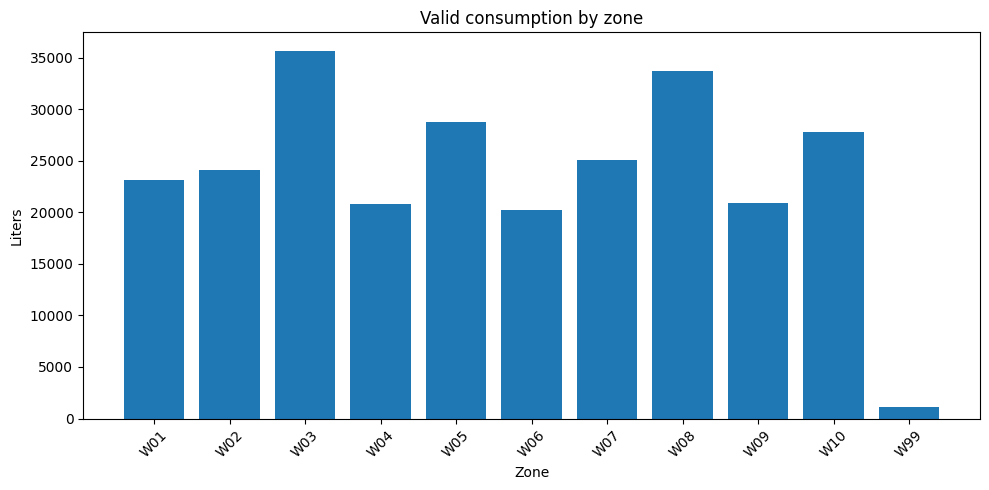

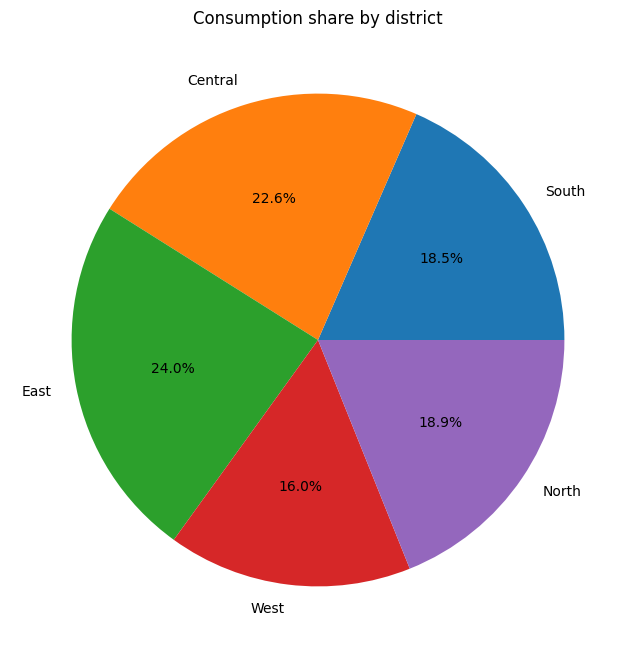

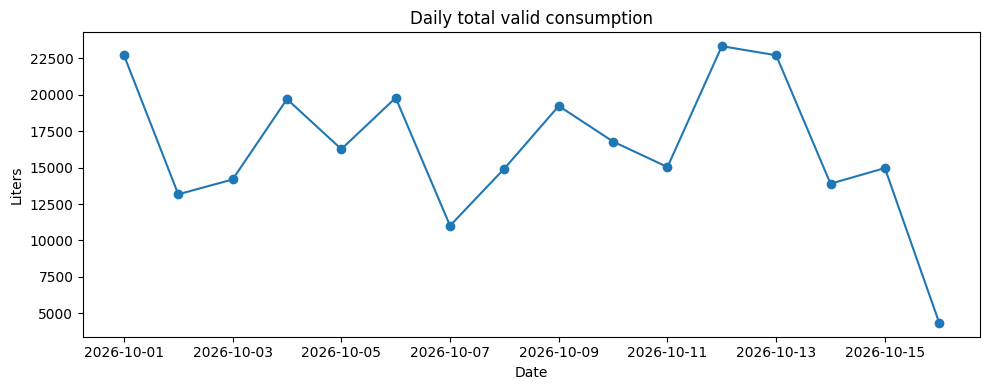

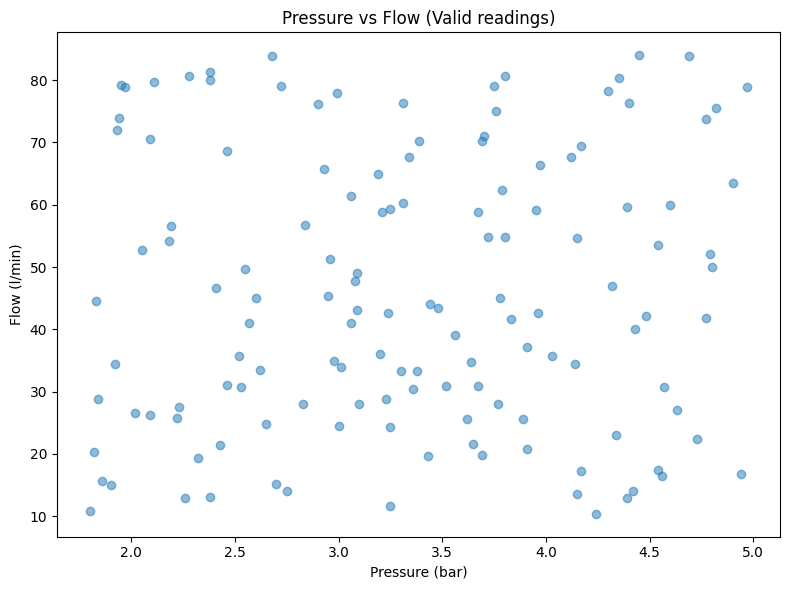

In [ ]:
import matplotlib.pyplot as plt

# Filter and prepare valid readings
valid_readings = valid.filter((F.col('reading_status') == 'Valid') & (F.col('consumption_liters') > 0))

# 1. Zone Chart (Bar Chart)
zone_chart = valid_readings.groupBy('zone_id').agg(F.sum('consumption_liters').alias('consumption')).orderBy('zone_id').toPandas()
zone_chart = zone_chart.dropna()  # Remove any rows with None values

plt.figure(figsize=(10, 5))
plt.bar(zone_chart['zone_id'].astype(str), zone_chart['consumption'])
plt.title('Valid consumption by zone')
plt.xlabel('Zone')
plt.ylabel('Liters')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. District Chart (Pie Chart)
district_chart = valid_readings.join(zones_flat, 'zone_id').groupBy('district').agg(F.sum('consumption_liters').alias('consumption')).toPandas()
district_chart = district_chart.dropna()  # Remove any rows with None values

plt.figure(figsize=(8, 8))
plt.pie(district_chart['consumption'], labels=district_chart['district'], autopct='%1.1f%%')
plt.title('Consumption share by district')
plt.show()

# 3. Daily Trend (Line Plot)
daily = valid_readings.withColumn('reading_day', F.to_date('reading_time')).groupBy('reading_day').agg(F.sum('consumption_liters').alias('consumption')).orderBy('reading_day').toPandas()
daily = daily.dropna()

plt.figure(figsize=(10, 4))
plt.plot(daily['reading_day'], daily['consumption'], marker='o')
plt.title('Daily total valid consumption')
plt.xlabel('Date')
plt.ylabel('Liters')
plt.tight_layout()
plt.show()

# 4. Scatter Plot
scatter = valid_readings.select('pressure_bar', 'flow_lpm').dropna().toPandas()

plt.figure(figsize=(8, 6))
plt.scatter(scatter['pressure_bar'], scatter['flow_lpm'], alpha=0.5)
plt.title('Pressure vs Flow (Valid readings)')
plt.xlabel('Pressure (bar)')
plt.ylabel('Flow (l/min)')
plt.tight_layout()
plt.show()

### Question 55: Integrated Dashboard Summary Table

In [ ]:
quality=(readings.groupBy('zone_id').agg(F.avg('pressure_bar').alias('avg_pressure'),F.avg('chlorine_mg_l').alias('avg_chlorine'),F.sum((F.col('pressure_bar')<2.5).cast('int')).alias('low_pressure_count')))
req_summary=requests.groupBy('zone_id').agg(F.count('*').alias('service_request_count'),F.sum((F.col('priority')=='High').cast('int')).alias('high_priority_requests'))
dashboard=(zone_summary.join(quality,'zone_id','full').join(req_summary,'zone_id','left').fillna(0,['service_request_count','high_priority_requests','low_pressure_count']))
dashboard.orderBy('zone_id').show(100,False)

+-------+------------------+--------+-----------------+------------------+-------------+------------------+------------------+------------------+---------------------+----------------------+
|zone_id|zone_name         |district|total_consumption|avg_pressure      |reading_count|avg_pressure      |avg_chlorine      |low_pressure_count|service_request_count|high_priority_requests|
+-------+------------------+--------+-----------------+------------------+-------------+------------------+------------------+------------------+---------------------+----------------------+
|NULL   |NULL              |NULL    |NULL             |NULL              |NULL         |3.1               |0.52              |0                 |0                    |0                     |
|W01    |Old City          |Central |23107            |3.423076923076923 |13           |3.437333333333333 |0.8213333333333334|3                 |4                    |2                     |
|W02    |Hill View         |North   |24120   